# ML Classification Assignment

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)
(the same data is bundled with scikit-learn as `load_breast_cancer`)

**Task:** Binary classification — Malignant (0) vs Benign (1)

**Models:** Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes, Support Vector Machine

**Metrics:** Accuracy, AUC, Precision, Recall, F1 Score, Matthews Correlation Coefficient (MCC)

## Imports

In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    make_scorer,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
)

RANDOM_STATE = 42

## Step 1: Dataset Choice

**Why this dataset?**
- **569 instances** (≥ 500 required) and **30 numeric features** (≥ 12 required)
- No missing values, all features numeric — no imputation or encoding needed
- Moderate class imbalance (212 malignant / 357 benign), which makes MCC and AUC meaningful alongside accuracy

The 30 features are computed from digitized images of a fine needle aspirate (FNA) of a breast mass: for each of 10 cell-nucleus characteristics (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension) the **mean**, **standard error** and **worst** (largest) value are recorded.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print(f"Instances      : {X.shape[0]}")
print(f"Features       : {X.shape[1]}")
print(f"Missing values : {int(X.isna().sum().sum())}")
print(f"Classes        : 0 = {data.target_names[0]}, 1 = {data.target_names[1]}")
X.head()

Instances      : 569
Features       : 30
Missing values : 0
Classes        : 0 = malignant, 1 = benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Class distribution
class_counts = y.value_counts().sort_index().rename(index=dict(enumerate(data.target_names)))
pd.DataFrame({"count": class_counts, "percent": (class_counts / len(y) * 100).round(2)})

,count,percent
target,,
malignant,212,37.26
benign,357,62.74


In [4]:
# Summary statistics of the features
X.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### Class balance and feature correlation
Many features describe the same physical quantity (e.g. radius, perimeter and area), so they are strongly correlated. This matters for Naive Bayes, which assumes features are independent given the class.

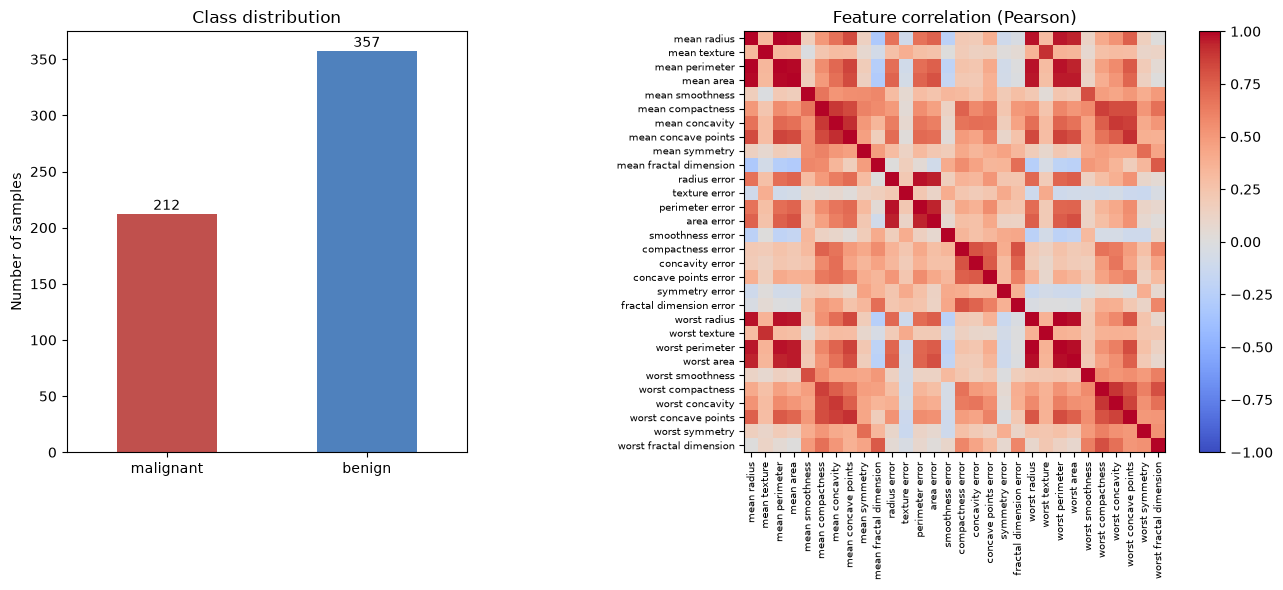

Feature pairs with |r| > 0.9: 21 of 435


,,|r|
mean radius,mean perimeter,0.998
worst radius,worst perimeter,0.994
mean radius,mean area,0.987
mean perimeter,mean area,0.987
worst radius,worst area,0.984
worst perimeter,worst area,0.978
radius error,perimeter error,0.973
mean perimeter,worst perimeter,0.970


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.7]})

class_counts.plot.bar(ax=ax1, color=["#c0504d", "#4f81bd"], rot=0)
ax1.set_title("Class distribution")
ax1.set_xlabel("")
ax1.set_ylabel("Number of samples")
for i, v in enumerate(class_counts):
    ax1.text(i, v + 4, str(v), ha="center")

corr = X.corr()
im = ax2.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax2.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax2.set_yticks(range(len(corr)), corr.columns, fontsize=7)
ax2.set_title("Feature correlation (Pearson)")
fig.colorbar(im, ax=ax2, fraction=0.046)
plt.tight_layout()
plt.show()

# Most strongly correlated feature pairs (upper triangle only, so each pair appears once)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
print(f"Feature pairs with |r| > 0.9: {(upper.abs() > 0.9).sum()} of {len(upper)}")
upper.abs().sort_values(ascending=False).head(8).round(3).rename("|r|").to_frame()

### Train / Test Split
A stratified 80/20 split keeps the malignant/benign ratio identical in the training and test sets.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train size: {len(X_train)}   Test size: {len(X_test)}")

Train size: 455   Test size: 114


## Step 2: Classification Models and Evaluation Metrics

### Evaluation helper
For each model we fit on the training set and compute all six metrics on the test set.
- **AUC** needs a continuous score: we use the predicted probability of class 1 where available, otherwise the SVM's signed distance to the decision boundary (`decision_function`).
- **Precision / Recall / F1** are reported for the positive class, which is scikit-learn's default `pos_label=1` = **benign**. Clinically, the costly error is a *missed malignant* case, so the malignant-class recall is also tracked separately (from the confusion matrix and classification report) and compared across models below.
- **MCC** ranges from −1 to +1 and is robust to class imbalance. Unlike precision/recall/F1 it does not depend on which class is called positive, so it is used to rank the models.

In [7]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
    }

    print(f"=== {name} ===")
    for k, v in metrics.items():
        print(f"{k:<10}: {v:.4f}")
    print("\nConfusion matrix (rows = actual, cols = predicted):")
    print(pd.DataFrame(
        confusion_matrix(y_test, y_pred),
        index=[f"actual {c}" for c in data.target_names],
        columns=[f"pred {c}" for c in data.target_names],
    ))
    print("\n" + classification_report(y_test, y_pred, target_names=data.target_names, digits=4))
    return metrics

results = {}

### Model 1: Logistic Regression
A linear model; features are standardized inside a `Pipeline` so the scaler is fit on training data only (no data leakage).

In [8]:
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
results["Logistic Regression"] = evaluate("Logistic Regression", lr)

=== Logistic Regression ===
Accuracy  : 0.9825
AUC       : 0.9954
Precision : 0.9861
Recall    : 0.9861
F1        : 0.9861
MCC       : 0.9623

Confusion matrix (rows = actual, cols = predicted):
                  pred malignant  pred benign
actual malignant              41            1
actual benign                  1           71

              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



### Model 2: Decision Tree Classifier
Tree models are scale-invariant, so no scaling is applied. `max_depth=5` limits overfitting.

In [9]:
dt = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
results["Decision Tree"] = evaluate("Decision Tree", dt)

=== Decision Tree ===
Accuracy  : 0.9211
AUC       : 0.9163
Precision : 0.9565
Recall    : 0.9167
F1        : 0.9362
MCC       : 0.8341

Confusion matrix (rows = actual, cols = predicted):
                  pred malignant  pred benign
actual malignant              39            3
actual benign                  6           66

              precision    recall  f1-score   support

   malignant     0.8667    0.9286    0.8966        42
      benign     0.9565    0.9167    0.9362        72

    accuracy                         0.9211       114
   macro avg     0.9116    0.9226    0.9164       114
weighted avg     0.9234    0.9211    0.9216       114



### Model 3: K-Nearest Neighbor Classifier
KNN is distance-based, so standardization is essential. `k = 5`.

In [10]:
knn = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=5)),
])
results["K-Nearest Neighbors"] = evaluate("K-Nearest Neighbors", knn)

=== K-Nearest Neighbors ===
Accuracy  : 0.9561
AUC       : 0.9788
Precision : 0.9589
Recall    : 0.9722
F1        : 0.9655
MCC       : 0.9054

Confusion matrix (rows = actual, cols = predicted):
                  pred malignant  pred benign
actual malignant              39            3
actual benign                  2           70

              precision    recall  f1-score   support

   malignant     0.9512    0.9286    0.9398        42
      benign     0.9589    0.9722    0.9655        72

    accuracy                         0.9561       114
   macro avg     0.9551    0.9504    0.9526       114
weighted avg     0.9561    0.9561    0.9560       114



### Model 4: Naive Bayes Classifier (Gaussian)
Gaussian NB is chosen because all features are continuous (Multinomial NB is meant for count data).

In [11]:
nb = GaussianNB()
results["Naive Bayes (Gaussian)"] = evaluate("Naive Bayes (Gaussian)", nb)

=== Naive Bayes (Gaussian) ===
Accuracy  : 0.9386
AUC       : 0.9878
Precision : 0.9452
Recall    : 0.9583
F1        : 0.9517
MCC       : 0.8676

Confusion matrix (rows = actual, cols = predicted):
                  pred malignant  pred benign
actual malignant              38            4
actual benign                  3           69

              precision    recall  f1-score   support

   malignant     0.9268    0.9048    0.9157        42
      benign     0.9452    0.9583    0.9517        72

    accuracy                         0.9386       114
   macro avg     0.9360    0.9315    0.9337       114
weighted avg     0.9384    0.9386    0.9384       114



### Model 5: Support Vector Machine
RBF-kernel SVM with standardized features.

In [12]:
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", random_state=RANDOM_STATE)),
])
results["Support Vector Machine"] = evaluate("Support Vector Machine", svm)

=== Support Vector Machine ===
Accuracy  : 0.9825
AUC       : 0.9950
Precision : 0.9861
Recall    : 0.9861
F1        : 0.9861
MCC       : 0.9623

Confusion matrix (rows = actual, cols = predicted):
                  pred malignant  pred benign
actual malignant              41            1
actual benign                  1           71

              precision    recall  f1-score   support

   malignant     0.9762    0.9762    0.9762        42
      benign     0.9861    0.9861    0.9861        72

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



## Comparison of All Models

In [13]:
results_df = pd.DataFrame(results).T.round(4)
results_df.index.name = "Model"
results_df.to_csv("model_comparison_results.csv", float_format="%.4f")
results_df.style.highlight_max(axis=0, color="lightgreen").format("{:.4f}")

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
Decision Tree,0.9211,0.9163,0.9565,0.9167,0.9362,0.8341
K-Nearest Neighbors,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
Naive Bayes (Gaussian),0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


In [14]:
best_mcc = results_df["MCC"].max()
best = results_df.index[results_df["MCC"] == best_mcc].tolist()
print(f"Best model(s) by MCC: {', '.join(best)} (MCC = {best_mcc:.4f})")

Best model(s) by MCC: Logistic Regression, Support Vector Machine (MCC = 0.9623)


### Cross-validation check (training set only)
The test set has only 114 samples, so one misclassification moves accuracy by 0.0088 — several of the gaps above are just one or two predictions. To check that the ranking is stable, each model is also scored with **stratified 5-fold cross-validation on the 455 training rows** (the test set is not touched). Mean ± standard deviation across the folds is shown.

In [15]:
fitted = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "K-Nearest Neighbors": knn,
    "Naive Bayes (Gaussian)": nb,
    "Support Vector Machine": svm,
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"Accuracy": "accuracy", "AUC": "roc_auc", "MCC": make_scorer(matthews_corrcoef)}

cv_rows = {}
for name, model in fitted.items():
    # cross_validate fits clones of the model, so the models trained above are not changed
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {
        f"CV {m}": f"{scores[f'test_{m}'].mean():.4f} ± {scores[f'test_{m}'].std():.4f}"
        for m in scoring
    }

cv_df = pd.DataFrame(cv_rows).T
cv_df.index.name = "Model"
cv_df

,CV Accuracy,CV AUC,CV MCC
Model,,,
Logistic Regression,0.9780 ± 0.0098,0.9959 ± 0.0050,0.9535 ± 0.0207
Decision Tree,0.9231 ± 0.0120,0.9344 ± 0.0157,0.8409 ± 0.0235
K-Nearest Neighbors,0.9626 ± 0.0112,0.9882 ± 0.0081,0.9208 ± 0.0238
Naive Bayes (Gaussian),0.9407 ± 0.0247,0.9877 ± 0.0061,0.8730 ± 0.0537
Support Vector Machine,0.9692 ± 0.0146,0.9956 ± 0.0048,0.9347 ± 0.0313


### Malignant-class view
Precision / Recall / F1 above treat benign as the positive class. The table below shows the clinically important side: how many of the 42 malignant test cases each model misses, and the malignant-class recall, precision and F1.

In [16]:
malignant_rows = {}
for name, model in fitted.items():
    y_pred = model.predict(X_test)
    malignant_rows[name] = {
        "Malignant missed (of 42)": int(((y_test == 0) & (y_pred == 1)).sum()),
        "Recall (malignant)": recall_score(y_test, y_pred, pos_label=0),
        "Precision (malignant)": precision_score(y_test, y_pred, pos_label=0),
        "F1 (malignant)": f1_score(y_test, y_pred, pos_label=0),
    }
malignant_df = pd.DataFrame(malignant_rows).T.round(4)
malignant_df["Malignant missed (of 42)"] = malignant_df["Malignant missed (of 42)"].astype(int)
malignant_df

,Malignant missed (of 42),Recall (malignant),Precision (malignant),F1 (malignant)
Logistic Regression,1,0.9762,0.9762,0.9762
Decision Tree,3,0.9286,0.8667,0.8966
K-Nearest Neighbors,3,0.9286,0.9512,0.9398
Naive Bayes (Gaussian),4,0.9048,0.9268,0.9157
Support Vector Machine,1,0.9762,0.9762,0.9762


### Confusion matrices and ROC curves

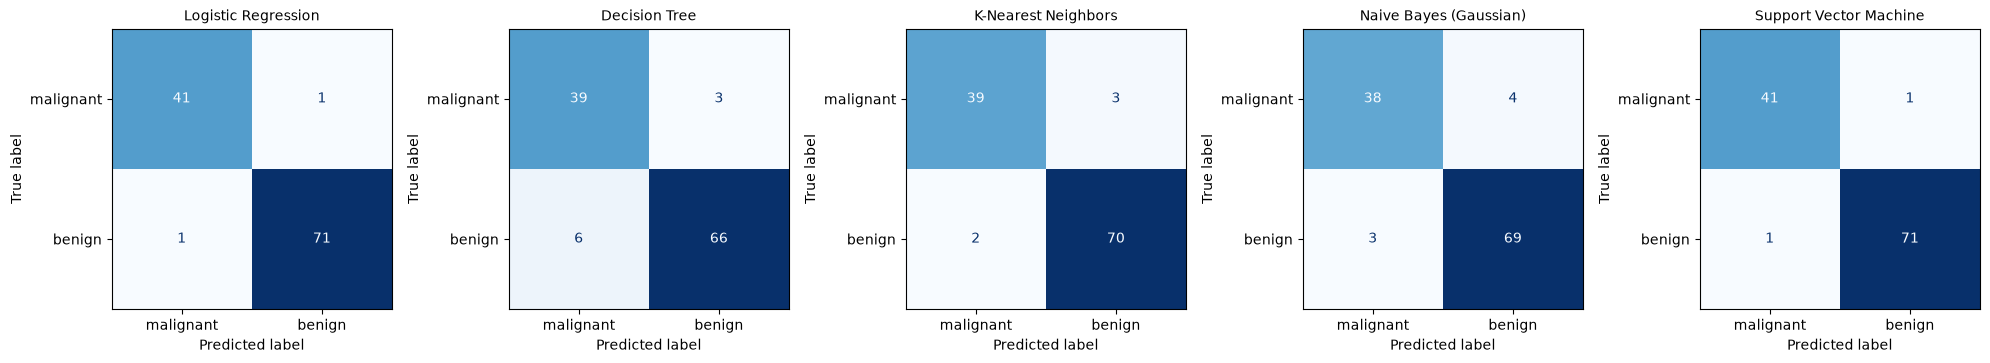

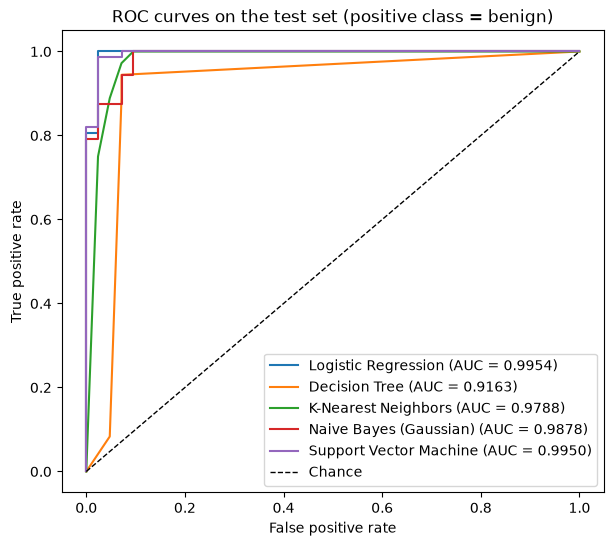

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (name, model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=data.target_names,
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

# Same scores as used for AUC in evaluate(): probability of class 1, or the SVM decision function
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in fitted.items():
    y_score = (model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba")
               else model.decision_function(X_test))
    fpr, tpr, _ = roc_curve(y_test, y_score)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_score):.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the test set (positive class = benign)")
ax.legend(loc="lower right")
plt.show()

## Export Trained Models
Each fitted model is saved to its own file in `models/` with `joblib` (scikit-learn's recommended serializer).
The scaled models are saved as full `Pipeline`s, so the `StandardScaler` is included and the loaded model can be used directly on raw feature values.

In [18]:
MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

trained_models = {
    "logistic_regression": lr,
    "decision_tree": dt,
    "knn": knn,
    "naive_bayes": nb,
    "svm": svm,
}

for file_name, model in trained_models.items():
    path = os.path.join(MODEL_DIR, f"{file_name}.pkl")
    joblib.dump(model, path)
    print(f"Saved {path:<35} ({os.path.getsize(path) / 1024:.1f} KB)")

# Held-out test split (features + target) for evaluating models in the Streamlit app.
X_test.assign(target=y_test).to_csv("test_data.csv", index=False)
print("Saved test_data.csv")

Saved models/logistic_regression.pkl      (3.0 KB)
Saved models/decision_tree.pkl            (4.3 KB)
Saved models/knn.pkl                      (112.9 KB)
Saved models/naive_bayes.pkl              (2.5 KB)
Saved models/svm.pkl                      (28.2 KB)
Saved test_data.csv


### Verify the exported models
Reload every model from disk and confirm it makes exactly the same predictions on the test set as the in-memory model.

In [19]:
for file_name, model in trained_models.items():
    loaded = joblib.load(os.path.join(MODEL_DIR, f"{file_name}.pkl"))
    same = (loaded.predict(X_test) == model.predict(X_test)).all()
    acc = accuracy_score(y_test, loaded.predict(X_test))
    print(f"{file_name:<20} reloaded OK | identical predictions: {same} | test accuracy: {acc:.4f}")

logistic_regression  reloaded OK | identical predictions: True | test accuracy: 0.9825
decision_tree        reloaded OK | identical predictions: True | test accuracy: 0.9211
knn                  reloaded OK | identical predictions: True | test accuracy: 0.9561
naive_bayes          reloaded OK | identical predictions: True | test accuracy: 0.9386
svm                  reloaded OK | identical predictions: True | test accuracy: 0.9825


### Using an exported model
```python
import joblib
from sklearn.datasets import load_breast_cancer

model = joblib.load("models/logistic_regression.pkl")
X = load_breast_cancer(as_frame=True).data
model.predict(X.head())   # 0 = malignant, 1 = benign
```
Input must have the same 30 features in the same order as training.

## Observations

*Note:* Precision, Recall and F1 in the comparison table are for the positive class **benign (1)**, scikit-learn's default. The malignant-class view (missed malignant cases, malignant recall) is given separately above; MCC is class-symmetric and is used for ranking.

| Model | Observation |
|---|---|
| **Logistic Regression** | Best overall. Ties SVM on test Accuracy, Precision, Recall, F1 and MCC (0.9623, 2 errors, 1 malignant missed) and has the highest test AUC (0.9954 vs 0.9950 for SVM). It is also clearly best in 5-fold cross-validation (CV MCC 0.954 ± 0.021). After standardization the classes are nearly linearly separable, so a simple linear boundary works extremely well. |
| **Decision Tree** | Weakest model overall: lowest test Accuracy, AUC, Recall, F1 and MCC (0.834; 9 errors, 3 malignant missed), and lowest in CV (MCC 0.841). Axis-aligned splits struggle with this smooth, correlated feature space, and a single tree has high variance. |
| **K-Nearest Neighbors** | Strong (test MCC 0.905, CV MCC 0.921) thanks to scaling, but misses 3 malignant cases; errors are near the class boundary where neighbours of both classes mix. |
| **Naive Bayes (Gaussian)** | High AUC (test 0.988) — it ranks samples well — but lower MCC (0.868) with 4 malignant missed, and the least stable model in CV (MCC 0.873 ± 0.054). 21 feature pairs have \|r\| > 0.9 (e.g. mean radius / mean perimeter, r = 0.998), which violates the independence assumption. |
| **Support Vector Machine** | Ties Logistic Regression on the test set (same 2 errors, 1 malignant missed; AUC 0.9950). In CV it is slightly behind LR (MCC 0.935 vs 0.954), so the RBF kernel's extra flexibility brings no gain over a linear model here. |

**Conclusion:** Logistic Regression and SVM are the best performers on the test set (only 2 misclassifications out of 114 each). Cross-validation on the training set breaks the tie in favour of **Logistic Regression**, which is also simpler and more interpretable, so it is the preferred model. Ranking by test MCC: LR = SVM > KNN > Naive Bayes > Decision Tree (CV MCC gives the same order, with LR ahead of SVM).